# **Six-Week Forecasting of White Rabbit Fear & Greed**

This notebook develops a separate forecasting study. It does not change the same-day calibration experiment in estimator_new_frame.ipynb.


## 1. Purpose and Research Question

The calibration notebook estimates the Fear & Greed (F&G) score for a date using that date's market-component scores. This notebook asks a different question:

> **At the end of the current market week, how accurately can the next six weekly levels of CNN's Fear & Greed series be forecast from information observed up to that point?**

The study uses White Rabbit's full available target history on CNN F&G, then compares three definitions of a weekly F&G target, simple benchmarks, statistical models, and a GRU. Since White Rabbit's target provenance changes between its pre-2021 archive and the CNN-backed period, performance is reported both over the full sample and by source era.


## 2. Target, Data Sources, and Information Timing

### Forecast target

The target is White Rabbit's full available fear_greed_score history: pre-2021 observations labeled third_party_archive and observations from 2021-02-01 onward labeled cnn_endpoint. The two eras are both included in training and chronological evaluation. Their provenance is retained so results can also be compared by source era; the archive is not silently treated as identical in origin to the CNN-backed scores.

The target is **not** the estimator's own equal-weight value: that is an input candidate, not the reference outcome.

### Forecast origin and available inputs

A forecast origin is the end of a complete Friday-ending market week. For each origin, models may use only target and component-score observations available through that week. No future component values are passed to a model. Univariate models use the target history; VAR/VECM and the GRU also use component scores. The timing assumption is that score inputs dated through Friday are available at the Friday forecast origin. In particular, this notebook does not reconstruct vintage availability for delayed or revised FRED series, so it is a historical weekly backtest rather than a point-in-time trading simulation.

### Three weekly target definitions

- **Last value:** the final observed daily White Rabbit score in the week; answers “what will the week-ending sentiment level be?”
- **Mean:** average daily White Rabbit score across observed market days; answers “what will the week's average sentiment be?”
- **Median:** median daily score; describes the typical week and is less affected by a single daily spike.

The same aggregation is applied to component-score inputs so each weekly dataset aligns its predictors and target. These targets are different estimands, so the lowest error alone does not decide which one best answers the research question.


## 3. Reproducible Data Loading

The loader builds the project's component scores and joins them to White Rabbit by date. source="all" requests both source eras. Weekly targets use every observed Rabbit score; component inputs are aggregated from the estimator history. Any internal missing weekly target is carried forward from the past to preserve the regular calendar, and a mask keeps that synthetic value out of evaluation metrics. The source-specific target counts and effective feature list are displayed below.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from load_calibration_data import load_calibration_data
from forecast_benchmarks import (
    AGGREGATIONS,
    MODEL_NAMES,
    build_weekly_datasets,
    forecast_latest_scenarios,
    plot_backtest_metrics,
    plot_latest_forecasts,
    rolling_origin_backtest,
    summarize_backtest,
)

plt.rcParams.update({
    "figure.facecolor": "#0f0f0f",
    "axes.facecolor":   "#1a1a1a",
    "axes.edgecolor":   "#444",
    "grid.color":       "#333",
    "text.color":       "#e0e0e0",
    "axes.labelcolor":  "#e0e0e0",
    "xtick.color":      "#888",
    "ytick.color":      "#888",
    "font.family":      "monospace",
})

calibration_df = load_calibration_data(
    start_date="2005-01-01",
    history_start="2005-01-01",
    source="all",
)

target_rows = calibration_df.dropna(subset=["fear_greed_score"])
load_summary = pd.Series(
    {
        "first joined estimator date": calibration_df.index.min().date(),
        "last joined estimator date": calibration_df.index.max().date(),
        "daily estimator rows": len(calibration_df),
        "all White Rabbit target rows": len(target_rows),
        "component score columns available": len(calibration_df.attrs["feature_columns"]),
        "White Rabbit source URL": calibration_df.attrs["white_rabbit_source_url"],
        "fetched at (UTC)": calibration_df.attrs["white_rabbit_fetched_at_utc"],
    },
    name="value",
)
display(load_summary.to_frame())

source_summary = pd.DataFrame(
    [
        {
            "source": source,
            "target days": len(group),
            "first target date": group.index.min().date(),
            "last target date": group.index.max().date(),
        }
        for source, group in target_rows.groupby("source", sort=True)
    ]
).set_index("source")
display(source_summary)


[INFO]: Using simple average for F&G estimation.


,value
first joined estimator date,2005-12-20
last joined estimator date,2026-10-08
daily estimator rows,5428
all White Rabbit target rows,3941
component score columns available,8
White Rabbit source URL,https://raw.githubusercontent.com/whit3rabbit/...
fetched at (UTC),2026-10-08T16:33:27.615575+00:00


,target days,first target date,last target date
source,,,
cnn_endpoint,1427,2021-02-01,2026-10-07
third_party_archive,2514,2011-01-03,2021-01-29


## 4. Construct and Inspect Weekly Target Candidates

The data are grouped into weeks ending Friday. If the latest available observation falls before the current Friday, that partial week is removed so it cannot become the forecast origin. Holiday weeks retain their actual observed market days.


,weeks on regular calendar,weeks with observed target,weeks target carried forward,weeks with component carry-forward,first week,last complete week,observed target mean,observed target std,observed target min,observed target max,archive target days available,archive target days with complete inputs,CNN target days available,CNN target days with complete inputs,component columns used,components excluded
last,822,818,4,0,2011-01-07,2026-10-02,48.830353,21.08725,1.0,95.0,2514,2514,1427,1427,7,score_put_call
mean,822,818,4,0,2011-01-07,2026-10-02,48.870995,20.502408,2.4,93.25,2514,2514,1427,1427,7,score_put_call
median,822,818,4,0,2011-01-07,2026-10-02,48.883076,20.713453,2.0,94.0,2514,2514,1427,1427,7,score_put_call


Component inputs used in both source eras: ['score_momentum_spx', 'score_strength_proxy', 'score_breadth_rsp_spx', 'score_safe_haven_20d', 'score_junk_bond_mom_20d', 'score_hy_spread', 'score_vix_rel']


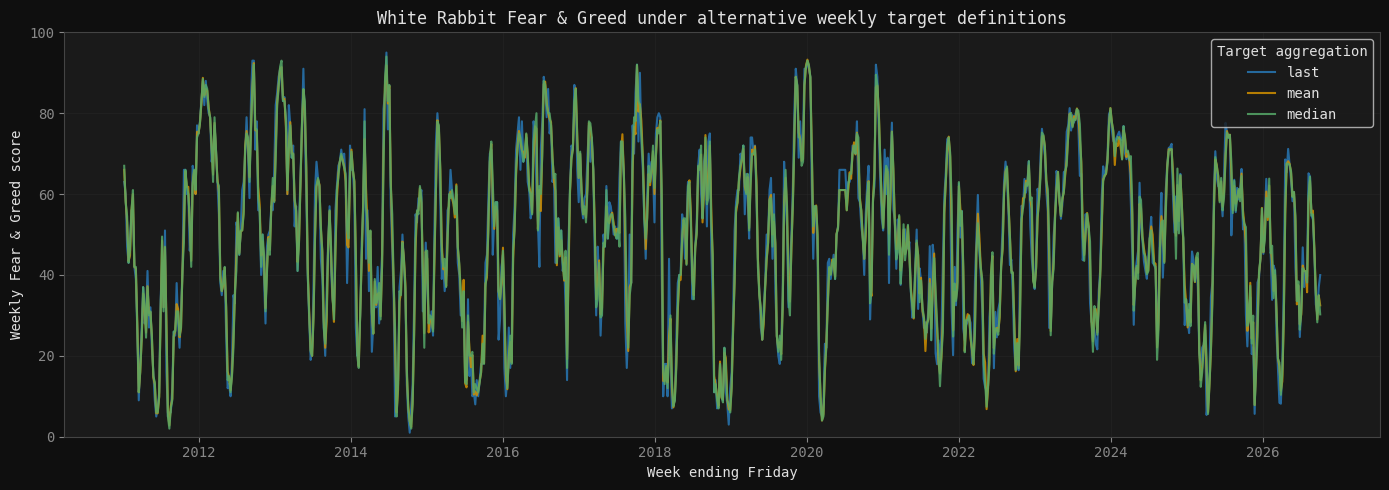

In [2]:
weekly_frames = build_weekly_datasets(
    calibration_df,
    aggregations=AGGREGATIONS,
    week_rule="W-FRI",
)

weekly_summary = pd.DataFrame(
    {
        aggregation: {
            "weeks on regular calendar": len(frame),
            "weeks with observed target": frame.attrs["observed_target_weeks"],
            "weeks target carried forward": frame.attrs["carried_target_weeks"],
            "weeks with component carry-forward": frame.attrs["feature_imputed_weeks"],
            "first week": frame.index.min().date(),
            "last complete week": frame.index.max().date(),
            "observed target mean": frame.attrs["observed_target_mean"],
            "observed target std": frame.attrs["observed_target_std"],
            "observed target min": frame.attrs["observed_target_min"],
            "observed target max": frame.attrs["observed_target_max"],
            "archive target days available": frame.attrs["source_target_days"].get("third_party_archive", 0),
            "archive target days with complete inputs": frame.attrs["complete_days_by_source"].get("third_party_archive", 0),
            "CNN target days available": frame.attrs["source_target_days"].get("cnn_endpoint", 0),
            "CNN target days with complete inputs": frame.attrs["complete_days_by_source"].get("cnn_endpoint", 0),
            "component columns used": len(frame.attrs["feature_columns"]),
            "components excluded": ", ".join(frame.attrs["excluded_feature_columns"]) or "None",
        }
        for aggregation, frame in weekly_frames.items()
    }
).T
display(weekly_summary.round(2))

print("Component inputs used in both source eras:", weekly_frames["last"].attrs["feature_columns"])

fig, ax = plt.subplots(figsize=(14, 5))
colors = {"last": "#2878B5", "mean": "#D18F00", "median": "#55A868"}
for aggregation, frame in weekly_frames.items():
    ax.plot(frame.index, frame["target"], label=aggregation, color=colors[aggregation], alpha=0.85)
ax.set_title("White Rabbit Fear & Greed under alternative weekly target definitions")
ax.set_xlabel("Week ending Friday")
ax.set_ylabel("Weekly Fear & Greed score")
ax.set_ylim(0, 100)
ax.grid(alpha=0.25)
ax.legend(title="Target aggregation")
plt.tight_layout()
plt.show()


## 5. Forecasting Protocol and Leakage Controls

The forecast horizon is six weeks. The first 104 complete weekly observations form the minimum training history. Forecast origins then advance by six weeks, so the six target weeks in successive backtest blocks do not overlap. At each origin the training history expands only after the previous block's actuals would have become observable. The rolling backtest starts in the archive era, passes through the source transition, and ends in the CNN-backed era.

The current White Rabbit file has a four-week internal target gap in June–July 2020. The weekly frame carries the last observed target forward only to keep time steps equally spaced. This is a causal training input; those four weeks are marked unobserved and excluded from all error metrics. Component weeks with no value are handled the same way using the latest prior score. The summary reports how many weeks required either carry-forward.

MAE is the primary descriptive metric because it is measured directly in F&G points; RMSE is secondary and penalizes large misses more strongly. Metrics are reported separately for each forecast horizon (week 1 through week 6). Full-sample metrics summarize both source eras, while a source-stratified diagnostic helps reveal whether performance differs across the provenance break. Forecast origins are still serial observations, so these scores are comparative diagnostics rather than independent replications.

Candidate models are defined before running the backtest:

- **Seasonal Naive:** same week-of-year value from 52 weeks earlier.
- **Moving Average:** the mean of the last four weekly targets, repeated across the horizon.
- **ARIMA:** a small predeclared order set; AIC selects among it using only the training history at each origin ([statsmodels ARIMA](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html)).
- **VAR (first differences):** jointly forecasts changes in F&G and component scores, then converts those changes back to levels. BIC selects a lag up to four using only the training history. A VAR in levels assumes stationarity; this candidate differences the weekly vector first ([statsmodels VAR guide](https://www.statsmodels.org/stable/vector_ar.html)).
- **VECM:** jointly forecasts the levels when the Johansen trace test finds a cointegrating rank between 1 and K−1; otherwise that fold is reported as unavailable. Rank selection is repeated inside each training fold ([statsmodels VECM](https://www.statsmodels.org/stable/generated/statsmodels.tsa.vector_ar.vecm.VECM.html)).
- **GRU:** a direct multi-output recurrent model uses the previous 26 weeks of F&G and component scores to predict all six future weekly targets at once. It does not receive future inputs. Epoch selection uses a chronological validation tail inside each training fold ([PyTorch GRU](https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html)).

The archive adds substantially more weekly history than the CNN-only period, but the change in target provenance may also create a source break. Component inputs are limited to columns observed in both source eras. VAR/VECM can still be parameter-heavy with many inputs, and the GRU is a candidate rather than a presumed winner. statsmodels and PyTorch are optional notebook dependencies; install them in the notebook environment if imports are unavailable.


In [3]:
# Centralized settings make the backtest horizon and training assumptions explicit.
HORIZON_WEEKS = 6
INITIAL_TRAIN_WEEKS = 104
ORIGIN_STEP_WEEKS = 6  # Non-overlapping six-week evaluation blocks.
SEASON_LENGTH_WEEKS = 52
MOVING_AVERAGE_WINDOW_WEEKS = 4
GRU_LOOKBACK_WEEKS = 26
GRU_HIDDEN_SIZE = 32
GRU_MAX_EPOCHS = 100
GRU_PATIENCE = 12
RANDOM_STATE = 42

print(f"Models: {MODEL_NAMES}")
print(f"Target definitions: {AGGREGATIONS}")
print(
    f"Horizon: {HORIZON_WEEKS} weeks; minimum training history: "
    f"{INITIAL_TRAIN_WEEKS} weeks; origin step: {ORIGIN_STEP_WEEKS} weeks."
)


Models: ('Seasonal Naive', 'Moving Average', 'ARIMA', 'VAR (first differences)', 'VECM', 'GRU')
Target definitions: ('last', 'mean', 'median')
Horizon: 6 weeks; minimum training history: 104 weeks; origin step: 6 weeks.


## 6. Expanding-Window Backtest

Every aggregation/model pair is evaluated at the same forecast origins. An individual statistical candidate that cannot be estimated at an origin is recorded as unavailable rather than silently omitted. VECM failures are informative: they show when the sample does not support the cointegrated-level specification.


In [ ]:
backtest_frames = []

for aggregation, weekly_frame in weekly_frames.items():
    fold_predictions = rolling_origin_backtest(
        weekly_frame,
        horizon=HORIZON_WEEKS,
        initial_train_weeks=INITIAL_TRAIN_WEEKS,
        origin_step_weeks=ORIGIN_STEP_WEEKS,
        models=MODEL_NAMES,
        season_length=SEASON_LENGTH_WEEKS,
        moving_average_window=MOVING_AVERAGE_WINDOW_WEEKS,
        gru_lookback=GRU_LOOKBACK_WEEKS,
        gru_hidden_size=GRU_HIDDEN_SIZE,
        gru_max_epochs=GRU_MAX_EPOCHS,
        gru_patience=GRU_PATIENCE,
        random_state=RANDOM_STATE,
    )
    fold_predictions["aggregation"] = aggregation
    backtest_frames.append(fold_predictions)

backtest_predictions = pd.concat(backtest_frames, ignore_index=True)
backtest_metrics = summarize_backtest(backtest_predictions)

# Primary view: errors for each aggregation, model, and lead time.
display(
    backtest_metrics.sort_values(["aggregation", "horizon_weeks", "MAE"])
    .round(3)
    .reset_index(drop=True)
)

# A compact ranking summary; failed VECM folds remain visible in failed_origins.
overall_backtest_summary = (
    backtest_metrics.groupby(["aggregation", "model"])
    .agg(
        mean_horizon_MAE=("MAE", "mean"),
        mean_horizon_RMSE=("RMSE", "mean"),
        mean_origins=("n_origins", "mean"),
        failed_origins=("failed_origins", "sum"),
    )
    .sort_values(["aggregation", "mean_horizon_MAE"])
)
display(overall_backtest_summary.round(3))
plot_backtest_metrics(backtest_metrics)


c:\Users\aurel\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\aurel\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\aurel\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
c:\Users\aurel\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been pro

## 7. Results: Compare Models, Target Definitions, and Source Eras

Inspect the horizon-specific full-sample table and MAE plot, then use the source-stratified table in the next cell. Ask separately:

1. Which target definition best matches the intended meaning: week-ending level, average weekly sentiment, or typical weekly sentiment?
2. Within each target definition, which model has the lowest average MAE and does it remain competitive at weeks 4–6?
3. Does the ranking hold in both the archive and CNN-backed eras, or is it driven by one source period?
4. Is the result stable across forecast origins, or driven by a few volatile periods?
5. Did VECM succeed often enough to make its error summary meaningful?

Do not describe one aggregation as “more accurate” without naming the estimand it predicts. Do not treat the archive-versus-CNN comparison as a clean model-only comparison: the source era and market regime both change over time. Do not infer a daily path by interpolating these six weekly forecasts; that would add assumptions not evaluated here.


In [ ]:
# Label each evaluated target week by the White Rabbit source era represented
# in the complete daily rows used to construct the weekly target.
source_by_week = weekly_frames["last"].attrs["target_source_by_week"]
source_scored = backtest_predictions.dropna(subset=["actual", "prediction"]).copy()
source_scored["target_source"] = pd.to_datetime(source_scored["target_date"]).map(source_by_week)
source_scored["absolute_error"] = (source_scored["actual"] - source_scored["prediction"]).abs()
source_scored["squared_error"] = (source_scored["actual"] - source_scored["prediction"]) ** 2

source_sensitivity_metrics = (
    source_scored.groupby(
        ["target_source", "aggregation", "model", "horizon"],
        dropna=False,
    )
    .agg(
        n_weeks=("actual", "size"),
        MAE=("absolute_error", "mean"),
        mean_squared_error=("squared_error", "mean"),
    )
    .reset_index()
)
source_sensitivity_metrics["RMSE"] = source_sensitivity_metrics["mean_squared_error"] ** 0.5
source_sensitivity_metrics = source_sensitivity_metrics.rename(
    columns={"horizon": "horizon_weeks"}
).drop(columns="mean_squared_error")

display(
    source_sensitivity_metrics.sort_values(
        ["target_source", "aggregation", "horizon_weeks", "MAE"]
    ).round(3).reset_index(drop=True)
)

origin_diagnostics = (
    backtest_predictions.groupby(["aggregation", "model", "status"], dropna=False)
    .agg(
        origin_count=("origin_date", "nunique"),
        first_origin=("origin_date", "min"),
        last_origin=("origin_date", "max"),
    )
    .reset_index()
)
display(origin_diagnostics)


## 8. Six-Week Forecast from the Latest Complete Week

The next cell fits every candidate to the latest complete weekly history under each target definition. It returns three sets of six-week trajectories because last, mean, and median targets answer different questions. It intentionally does not select a winner or save a forecast model automatically; choose the target definition and candidate only after reviewing the backtest and the intended use.


In [ ]:
latest_forecasts = forecast_latest_scenarios(
    weekly_frames,
    horizon=HORIZON_WEEKS,
    models=MODEL_NAMES,
    season_length=SEASON_LENGTH_WEEKS,
    moving_average_window=MOVING_AVERAGE_WINDOW_WEEKS,
    gru_lookback=GRU_LOOKBACK_WEEKS,
    gru_hidden_size=GRU_HIDDEN_SIZE,
    gru_max_epochs=GRU_MAX_EPOCHS,
    gru_patience=GRU_PATIENCE,
    random_state=RANDOM_STATE,
)

display(
    latest_forecasts.pivot_table(
        index=["aggregation", "target_date", "horizon"],
        columns="model",
        values="prediction",
    ).round(2)
)

unavailable_forecasts = latest_forecasts.loc[latest_forecasts["prediction"].isna()]
if not unavailable_forecasts.empty:
    display(unavailable_forecasts[["aggregation", "model", "status"]].drop_duplicates())

plot_latest_forecasts(weekly_frames, latest_forecasts)


## 9. Robustness, Interpretation, and Next Steps

- The White Rabbit score and market components are serially dependent. Non-overlapping six-week backtest blocks reduce direct overlap between test targets but do not make origins statistically independent.
- Including the pre-2021 third-party archive increases the available history. Its provenance differs from the post-2021 CNN-backed endpoint, so a source break may affect the target distribution. Report both full-sample and source-stratified results; archive scores are not an independent CNN observation.
- VAR/VECM can be unstable with many component inputs; the VECM is included only when a training-fold cointegration test supports a nontrivial rank.
- F&G is bounded from 0 to 100, but ARIMA, VAR/VECM, and GRU forecasts are not constrained to that range. Report raw forecasts and metrics; if an operational system later clips them, evaluate that transformed version separately.
- The weekly aggregation choice changes the quantity being predicted. Pick it based on the question the forecast should answer, then report the other definitions as sensitivity checks.
- The final six-week path is a genuine future forecast only after the latest complete week. The latest model is trained on the combined archive-plus-CNN target history. Once outcomes arrive, add them as a new untouched evaluation block.
- Keep these results separate from same-day calibration. The components are available only through the forecast origin; no future realized inputs are used.

After reviewing the backtest, record the chosen target estimand, model, settings, and latest-origin date. Then compare the realized six-week outcomes with the saved forecast once that period is complete.
